In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re

In [2]:
df = pd.read_csv("../data/skincare_products.csv")

In [3]:
df

,product_name,product_url,product_type,ingredients,price
0,The Ordinary Natural Moisturising Factors + HA...,https://www.lookfantastic.com/the-ordinary-nat...,Moisturiser,"Aqua (Water), Caprylic/Capric Triglyceride, Ce...",£5.20
1,CeraVe Facial Moisturising Lotion SPF 25 52ml,https://www.lookfantastic.com/cerave-facial-mo...,Moisturiser,"Aqua/Water, Homosalate, Glycerin, Octocrylene,...",£13.00
2,The Ordinary Hyaluronic Acid 2% + B5 Hydration...,https://www.lookfantastic.com/the-ordinary-hya...,Moisturiser,"Aqua (Water), Sodium Hyaluronate, Sodium Hyalu...",£6.20
3,AMELIORATE Transforming Body Lotion 200ml,https://www.lookfantastic.com/ameliorate-trans...,Moisturiser,"Aqua/Water/Eau, Ammonium Lactate, C12-15 Alkyl...",£22.50
4,CeraVe Moisturising Cream 454g,https://www.lookfantastic.com/cerave-moisturis...,Moisturiser,"Purified Water, Glycerin, Ceteareth-20 and Cet...",£16.00
...,...,...,...,...,...
1133,Elemis Life Elixirs Embrace Bath and Shower El...,https://www.lookfantastic.com/elemis-life-elix...,Bath Oil,"Prunus Amygdalus Dulcis (Sweet Almond) Oil, TI...",£55.00
1134,Love Boo Splendidly Soothing Bath Soak (250ml),https://www.lookfantastic.com/love-boo-splendi...,Bath Oil,"Aqua, sodium lauroyl sarcosinate, sodium cocoa...",£10.99
1135,Elemis Life Elixirs Fortitude Bath and Shower ...,https://www.lookfantastic.com/elemis-life-elix...,Bath Oil,"Prunus Amygdalus Dulcis (Sweet Almond) Oil, TI...",£55.00
1136,Connock London Kukui Oil Soothing Bath & Showe...,https://www.lookfantastic.com/connock-london-k...,Bath Oil,"Caprylic/Capric Triglyceride, PEG-40 Sorbitan ...",£36.00


In [4]:
print(df.columns.tolist())

['product_name', 'product_url', 'product_type', 'ingredients', 'price']


In [5]:
df.shape

(1138, 5)

In [6]:
df.dtypes

product_name    str
product_url     str
product_type    str
ingredients     str
price           str
dtype: object

In [7]:
df["price"] = (
    df["price"]
    .str.replace("£", "", regex=False)
    .str.strip()
    .astype(float)
)

In [8]:
df.dtypes

product_name        str
product_url         str
product_type        str
ingredients         str
price           float64
dtype: object

In [9]:
exchange_rate = 126.63
df["Price_INR"] = df["price"] * exchange_rate

In [10]:
df

,product_name,product_url,product_type,ingredients,price,Price_INR
0,The Ordinary Natural Moisturising Factors + HA...,https://www.lookfantastic.com/the-ordinary-nat...,Moisturiser,"Aqua (Water), Caprylic/Capric Triglyceride, Ce...",5.20,658.4760
1,CeraVe Facial Moisturising Lotion SPF 25 52ml,https://www.lookfantastic.com/cerave-facial-mo...,Moisturiser,"Aqua/Water, Homosalate, Glycerin, Octocrylene,...",13.00,1646.1900
2,The Ordinary Hyaluronic Acid 2% + B5 Hydration...,https://www.lookfantastic.com/the-ordinary-hya...,Moisturiser,"Aqua (Water), Sodium Hyaluronate, Sodium Hyalu...",6.20,785.1060
3,AMELIORATE Transforming Body Lotion 200ml,https://www.lookfantastic.com/ameliorate-trans...,Moisturiser,"Aqua/Water/Eau, Ammonium Lactate, C12-15 Alkyl...",22.50,2849.1750
4,CeraVe Moisturising Cream 454g,https://www.lookfantastic.com/cerave-moisturis...,Moisturiser,"Purified Water, Glycerin, Ceteareth-20 and Cet...",16.00,2026.0800
...,...,...,...,...,...,...
1133,Elemis Life Elixirs Embrace Bath and Shower El...,https://www.lookfantastic.com/elemis-life-elix...,Bath Oil,"Prunus Amygdalus Dulcis (Sweet Almond) Oil, TI...",55.00,6964.6500
1134,Love Boo Splendidly Soothing Bath Soak (250ml),https://www.lookfantastic.com/love-boo-splendi...,Bath Oil,"Aqua, sodium lauroyl sarcosinate, sodium cocoa...",10.99,1391.6637
1135,Elemis Life Elixirs Fortitude Bath and Shower ...,https://www.lookfantastic.com/elemis-life-elix...,Bath Oil,"Prunus Amygdalus Dulcis (Sweet Almond) Oil, TI...",55.00,6964.6500
1136,Connock London Kukui Oil Soothing Bath & Showe...,https://www.lookfantastic.com/connock-london-k...,Bath Oil,"Caprylic/Capric Triglyceride, PEG-40 Sorbitan ...",36.00,4558.6800


In [11]:
df.describe()

,price,Price_INR
count,1138.000000,1138.000000
mean,24.021775,3041.877374
std,21.770652,2756.817638
min,1.950000,246.928500
25%,9.950000,1259.968500
50%,18.925000,2396.472750
75%,31.500000,3988.845000
max,230.000000,29124.900000


<Axes: xlabel='Price_INR', ylabel='Density'>

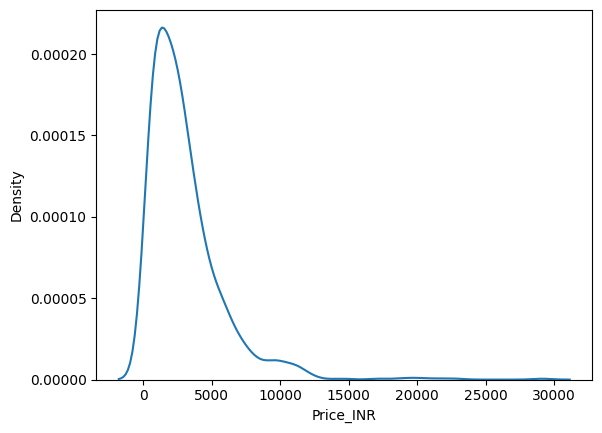

In [12]:
sns.kdeplot(df["Price_INR"])

<Axes: ylabel='Price_INR'>

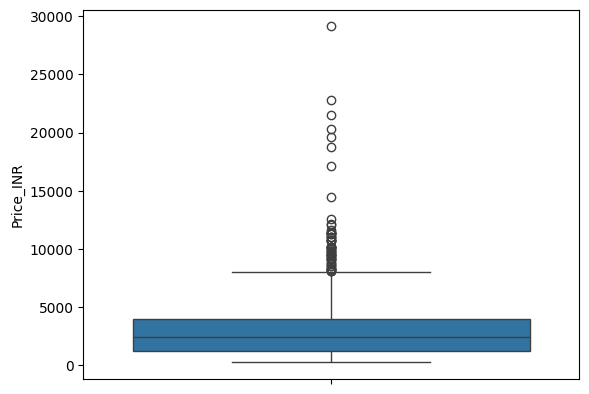

In [13]:
sns.boxplot(df["Price_INR"])

In [14]:
df.drop(df[df["Price_INR"] > 10000].index, inplace=True)

<Axes: ylabel='Price_INR'>

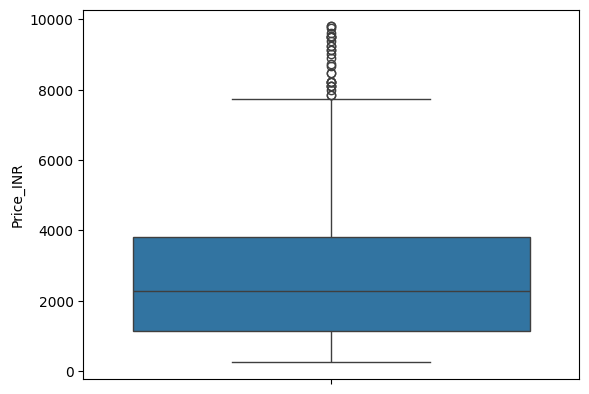

In [15]:
sns.boxplot(df["Price_INR"])

In [16]:
df.drop(df[df["Price_INR"] > 7000].index, inplace=True)

<Axes: ylabel='Price_INR'>

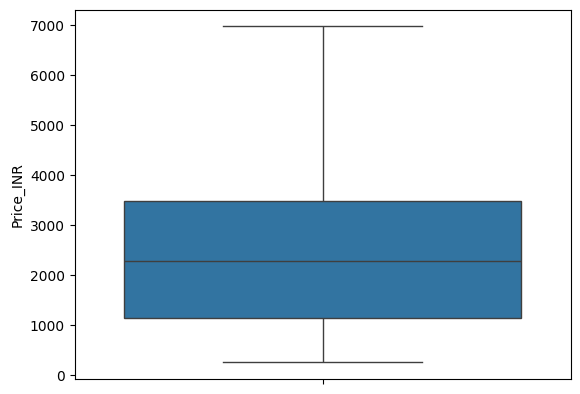

In [17]:
sns.boxplot(df["Price_INR"])

In [18]:
df.shape

(1058, 6)

In [19]:
df['product_type'].unique()

<ArrowStringArray>
['Moisturiser',       'Serum',         'Oil',        'Mist',        'Balm',
        'Mask',        'Peel',    'Eye Care',    'Cleanser',       'Toner',
  'Exfoliator',  'Bath Salts',   'Body Wash',    'Bath Oil']
Length: 14, dtype: str

In [20]:
df['product_type'].nunique()

14

<Axes: xlabel='count', ylabel='product_type'>

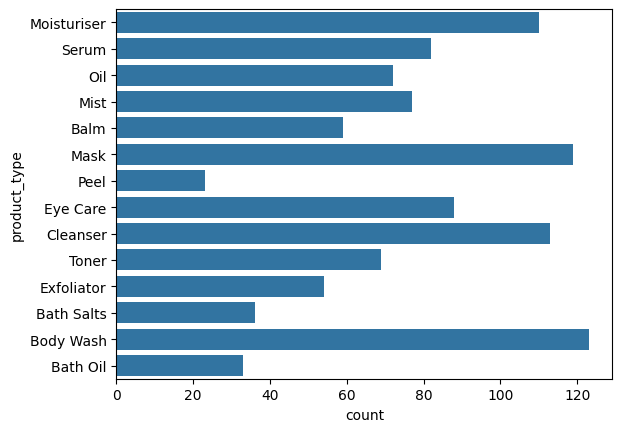

In [21]:
sns.countplot(df['product_type'])

In [22]:
df['ingredients'].nunique()

1018

In [23]:
df.duplicated().sum()

np.int64(0)

In [24]:
df.isnull().sum()

product_name    0
product_url     0
product_type    0
ingredients     0
price           0
Price_INR       0
dtype: int64

In [28]:
def clean_ingredients(text):
    if pd.isna(text):
        return ""

    text = str(text).lower()
    text = text.replace("\xa0", " ")
    text = re.sub(r"\s+", " ", text)

    ingredients = [
        item.strip()
        for item in text.split(",")
        if item.strip()
    ]

    return ", ".join(ingredients)


df["ingredients_clean"] = (
    df["ingredients"].apply(clean_ingredients)
)

display(
    df[
        ["product_name", "ingredients", "ingredients_clean"]
    ].head(5)
)

,product_name,ingredients,ingredients_clean
0,The Ordinary Natural Moisturising Factors + HA...,"Aqua (Water), Caprylic/Capric Triglyceride, Ce...","aqua (water), caprylic/capric triglyceride, ce..."
1,CeraVe Facial Moisturising Lotion SPF 25 52ml,"Aqua/Water, Homosalate, Glycerin, Octocrylene,...","aqua/water, homosalate, glycerin, octocrylene,..."
2,The Ordinary Hyaluronic Acid 2% + B5 Hydration...,"Aqua (Water), Sodium Hyaluronate, Sodium Hyalu...","aqua (water), sodium hyaluronate, sodium hyalu..."
3,AMELIORATE Transforming Body Lotion 200ml,"Aqua/Water/Eau, Ammonium Lactate, C12-15 Alkyl...","aqua/water/eau, ammonium lactate, c12-15 alkyl..."
4,CeraVe Moisturising Cream 454g,"Purified Water, Glycerin, Ceteareth-20 and Cet...","purified water, glycerin, ceteareth-20 and cet..."


In [25]:
df["ingredient_list"] = df["ingredients"].apply(
    lambda x: [item.strip() for item in x.split(",") if item.strip()]
)

display(
    df[["product_name", "ingredient_list"]].head(5)
)

,product_name,ingredient_list
0,The Ordinary Natural Moisturising Factors + HA...,"[Aqua (Water), Caprylic/Capric Triglyceride, C..."
1,CeraVe Facial Moisturising Lotion SPF 25 52ml,"[Aqua/Water, Homosalate, Glycerin, Octocrylene..."
2,The Ordinary Hyaluronic Acid 2% + B5 Hydration...,"[Aqua (Water), Sodium Hyaluronate, Sodium Hyal..."
3,AMELIORATE Transforming Body Lotion 200ml,"[Aqua/Water/Eau, Ammonium Lactate, C12-15 Alky..."
4,CeraVe Moisturising Cream 454g,"[Purified Water, Glycerin, Ceteareth-20 and Ce..."


In [28]:
df

,product_name,product_url,product_type,ingredients,price,Price_INR,ingredient_list
0,The Ordinary Natural Moisturising Factors + HA...,https://www.lookfantastic.com/the-ordinary-nat...,Moisturiser,"Aqua (Water), Caprylic/Capric Triglyceride, Ce...",5.20,658.4760,"[Aqua (Water), Caprylic/Capric Triglyceride, C..."
1,CeraVe Facial Moisturising Lotion SPF 25 52ml,https://www.lookfantastic.com/cerave-facial-mo...,Moisturiser,"Aqua/Water, Homosalate, Glycerin, Octocrylene,...",13.00,1646.1900,"[Aqua/Water, Homosalate, Glycerin, Octocrylene..."
2,The Ordinary Hyaluronic Acid 2% + B5 Hydration...,https://www.lookfantastic.com/the-ordinary-hya...,Moisturiser,"Aqua (Water), Sodium Hyaluronate, Sodium Hyalu...",6.20,785.1060,"[Aqua (Water), Sodium Hyaluronate, Sodium Hyal..."
3,AMELIORATE Transforming Body Lotion 200ml,https://www.lookfantastic.com/ameliorate-trans...,Moisturiser,"Aqua/Water/Eau, Ammonium Lactate, C12-15 Alkyl...",22.50,2849.1750,"[Aqua/Water/Eau, Ammonium Lactate, C12-15 Alky..."
4,CeraVe Moisturising Cream 454g,https://www.lookfantastic.com/cerave-moisturis...,Moisturiser,"Purified Water, Glycerin, Ceteareth-20 and Cet...",16.00,2026.0800,"[Purified Water, Glycerin, Ceteareth-20 and Ce..."
...,...,...,...,...,...,...,...
1133,Elemis Life Elixirs Embrace Bath and Shower El...,https://www.lookfantastic.com/elemis-life-elix...,Bath Oil,"Prunus Amygdalus Dulcis (Sweet Almond) Oil, TI...",55.00,6964.6500,"[Prunus Amygdalus Dulcis (Sweet Almond) Oil, T..."
1134,Love Boo Splendidly Soothing Bath Soak (250ml),https://www.lookfantastic.com/love-boo-splendi...,Bath Oil,"Aqua, sodium lauroyl sarcosinate, sodium cocoa...",10.99,1391.6637,"[Aqua, sodium lauroyl sarcosinate, sodium coco..."
1135,Elemis Life Elixirs Fortitude Bath and Shower ...,https://www.lookfantastic.com/elemis-life-elix...,Bath Oil,"Prunus Amygdalus Dulcis (Sweet Almond) Oil, TI...",55.00,6964.6500,"[Prunus Amygdalus Dulcis (Sweet Almond) Oil, T..."
1136,Connock London Kukui Oil Soothing Bath & Showe...,https://www.lookfantastic.com/connock-london-k...,Bath Oil,"Caprylic/Capric Triglyceride, PEG-40 Sorbitan ...",36.00,4558.6800,"[Caprylic/Capric Triglyceride, PEG-40 Sorbitan..."


In [29]:
df.to_csv("skincare_products_cleaned.csv", index=False)

In [27]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 products:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (1058, 7)

Column names:
['product_name', 'product_url', 'product_type', 'ingredients', 'price', 'Price_INR', 'ingredient_list']

First 5 products:


,product_name,product_url,product_type,ingredients,price,Price_INR,ingredient_list
0,The Ordinary Natural Moisturising Factors + HA...,https://www.lookfantastic.com/the-ordinary-nat...,Moisturiser,"Aqua (Water), Caprylic/Capric Triglyceride, Ce...",5.2,658.476,"[Aqua (Water), Caprylic/Capric Triglyceride, C..."
1,CeraVe Facial Moisturising Lotion SPF 25 52ml,https://www.lookfantastic.com/cerave-facial-mo...,Moisturiser,"Aqua/Water, Homosalate, Glycerin, Octocrylene,...",13.0,1646.190,"[Aqua/Water, Homosalate, Glycerin, Octocrylene..."
2,The Ordinary Hyaluronic Acid 2% + B5 Hydration...,https://www.lookfantastic.com/the-ordinary-hya...,Moisturiser,"Aqua (Water), Sodium Hyaluronate, Sodium Hyalu...",6.2,785.106,"[Aqua (Water), Sodium Hyaluronate, Sodium Hyal..."
3,AMELIORATE Transforming Body Lotion 200ml,https://www.lookfantastic.com/ameliorate-trans...,Moisturiser,"Aqua/Water/Eau, Ammonium Lactate, C12-15 Alkyl...",22.5,2849.175,"[Aqua/Water/Eau, Ammonium Lactate, C12-15 Alky..."
4,CeraVe Moisturising Cream 454g,https://www.lookfantastic.com/cerave-moisturis...,Moisturiser,"Purified Water, Glycerin, Ceteareth-20 and Cet...",16.0,2026.080,"[Purified Water, Glycerin, Ceteareth-20 and Ce..."



Missing values:
product_name       0
product_url        0
product_type       0
ingredients        0
price              0
Price_INR          0
ingredient_list    0
dtype: int64


In [32]:
print("Product types and counts:")
print(df["product_type"].value_counts())

print("\nUnique product types:")
print(df["product_type"].unique())

print("\nExample ingredients:")
for i in range(3):
    print(f"\n{df.iloc[i]['product_name']}")
    print(df.iloc[i]["ingredient_list"])

Product types and counts:
product_type
Body Wash      123
Mask           119
Cleanser       113
Moisturiser    110
Eye Care        88
Serum           82
Mist            77
Oil             72
Toner           69
Balm            59
Exfoliator      54
Bath Salts      36
Bath Oil        33
Peel            23
Name: count, dtype: int64

Unique product types:
<ArrowStringArray>
['Moisturiser',       'Serum',         'Oil',        'Mist',        'Balm',
        'Mask',        'Peel',    'Eye Care',    'Cleanser',       'Toner',
  'Exfoliator',  'Bath Salts',   'Body Wash',    'Bath Oil']
Length: 14, dtype: str

Example ingredients:

The Ordinary Natural Moisturising Factors + HA 30ml
['Aqua (Water)', 'Caprylic/Capric Triglyceride', 'Cetyl Alcohol', 'Propanediol', 'Stearyl Alcohol', 'Glycerin', 'Sodium Hyaluronate', 'Arginine', 'Aspartic Acid', 'Glycine', 'Alanine', 'Serine', 'Valine', 'Isoleucine', 'Proline', 'Threonine', 'Histidine', 'Phenylalanine', 'Glucose', 'Maltose', 'Fructose', 'Trehalos

In [33]:
from ast import literal_eval

def clean_ingredients(value):
    if isinstance(value, list):
        items = value

    elif isinstance(value, str):
        try:
            parsed = literal_eval(value)

            if isinstance(parsed, list):
                items = parsed
            else:
                items = value.split(",")

        except (ValueError, SyntaxError):
            items = value.split(",")

    else:
        return ""

    return ", ".join(
        str(item).strip().strip("'\"[]")
        for item in items
        if str(item).strip()
    )

df["ingredients_clean"] = df["ingredient_list"].apply(clean_ingredients)

print(df[["product_name", "product_type", "Price_INR",
          "ingredients_clean"]].head(3))

                                        product_name product_type  Price_INR  \
0  The Ordinary Natural Moisturising Factors + HA...  Moisturiser    658.476   
1      CeraVe Facial Moisturising Lotion SPF 25 52ml  Moisturiser   1646.190   
2  The Ordinary Hyaluronic Acid 2% + B5 Hydration...  Moisturiser    785.106   

                                   ingredients_clean  
0  Aqua (Water), Caprylic/Capric Triglyceride, Ce...  
1  Aqua/Water, Homosalate, Glycerin, Octocrylene,...  
2  Aqua (Water), Sodium Hyaluronate, Sodium Hyalu...  


In [34]:
from collections import Counter

ingredient_counts = Counter()

for ingredients in df["ingredient_list"]:
    if isinstance(ingredients, list):
        ingredient_counts.update(
            str(item).strip().lower() for item in ingredients
        )
    elif isinstance(ingredients, str):
        ingredient_counts.update(
            item.strip().lower()
            for item in ingredients.split(",")
        )

print("Top 20 ingredients:")
for ingredient, count in ingredient_counts.most_common(20):
    print(f"{ingredient}: {count}")

Top 20 ingredients:
glycerin: 694
phenoxyethanol: 496
citric acid: 342
limonene: 326
linalool: 313
disodium edta: 303
butylene glycol: 297
tocopherol: 251
sodium hydroxide: 246
sodium hyaluronate: 245
aqua (water): 240
xanthan gum: 219
caprylyl glycol: 216
ethylhexylglycerin: 216
sodium benzoate: 204
tocopheryl acetate: 193
geraniol: 182
potassium sorbate: 181
sodium chloride: 175
caprylic/capric triglyceride: 173


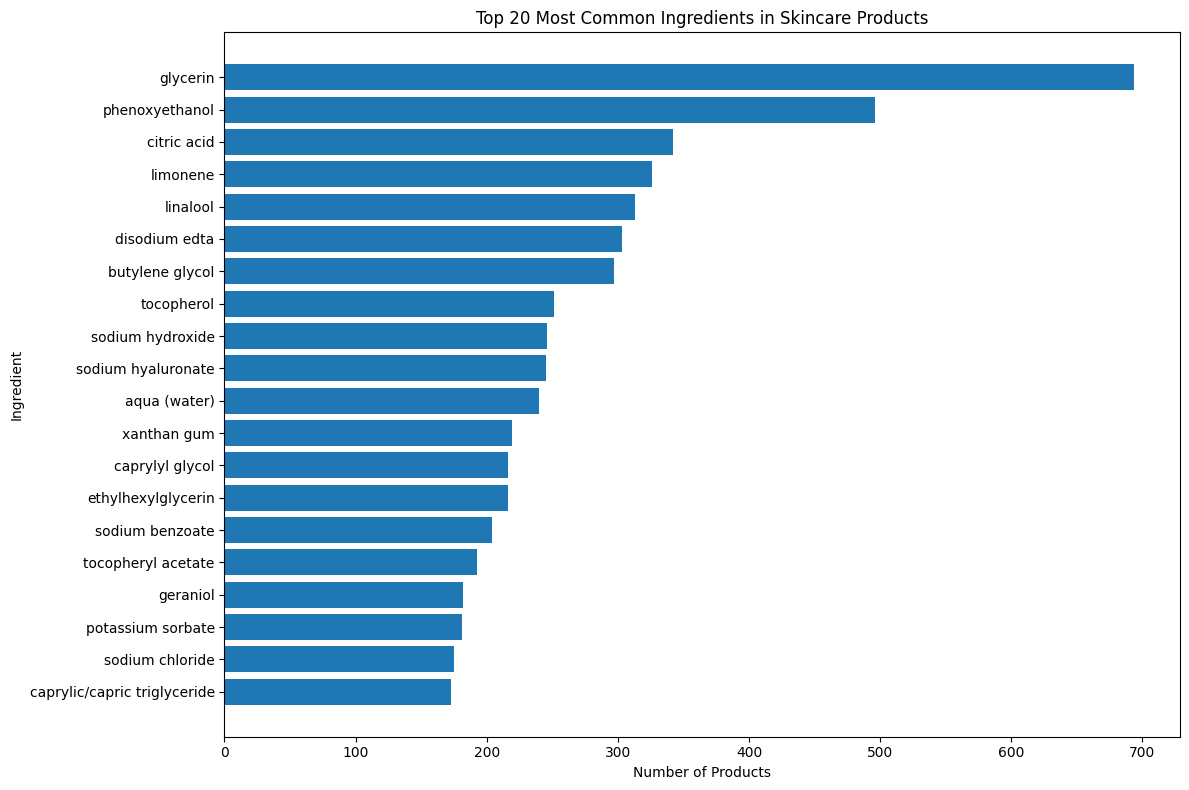

In [35]:
import matplotlib.pyplot as plt

top_20 = ingredient_counts.most_common(20)

ingredients = [item[0] for item in top_20]
counts = [item[1] for item in top_20]

plt.figure(figsize=(12, 8))
plt.barh(ingredients[::-1], counts[::-1])
plt.xlabel("Number of Products")
plt.ylabel("Ingredient")
plt.title("Top 20 Most Common Ingredients in Skincare Products")
plt.tight_layout()
plt.show()

In [36]:
def recommend_products_scored(
    df,
    skin_label,
    budget=1000,
    product_type=None,
    ingredient_keywords=None,
    top_n=5
):
    results = df.copy()

    results["Price_INR"] = pd.to_numeric(
        results["Price_INR"], errors="coerce"
    )

    results = results[
        results["Price_INR"].notna()
        & (results["Price_INR"] <= budget)
    ].copy()

    if product_type:
        results = results[
            results["product_type"].str.lower()
            == product_type.lower()
        ].copy()

    results["ingredients_clean"] = (
        results["ingredients_clean"].fillna("").str.lower()
    )

    keywords = [
        word.lower()
        for word in (ingredient_keywords or [])
    ]

    if keywords:
        results["ingredient_matches"] = results[
            "ingredients_clean"
        ].apply(
            lambda text: sum(
                keyword in text for keyword in keywords
            )
        )

        results = results[
            results["ingredient_matches"] > 0
        ].copy()
    else:
        results["ingredient_matches"] = 0

    # Ingredient match score, with lower price as a tie-breaker
    results = results.sort_values(
        ["ingredient_matches", "Price_INR"],
        ascending=[False, True]
    )

    results["rank"] = range(1, len(results) + 1)

    return results[
        [
            "rank",
            "product_name",
            "product_type",
            "Price_INR",
            "ingredient_matches",
            "ingredients_clean",
            "product_url"
        ]
    ].head(top_n).reset_index(drop=True)

In [37]:
recommendations = recommend_products_scored(
    df=df,
    skin_label="dry",
    budget=1000,
    product_type="Moisturiser",
    ingredient_keywords=["glycerin", "sodium hyaluronate"],
    top_n=5
)

recommendations

,rank,product_name,product_type,Price_INR,ingredient_matches,ingredients_clean,product_url
0,1,The Ordinary Natural Moisturising Factors + HA...,Moisturiser,658.4760,2,"aqua (water), caprylic/capric triglyceride, ce...",https://www.lookfantastic.com/the-ordinary-nat...
1,2,The Ordinary Hyaluronic Acid 2% + B5 Hydration...,Moisturiser,785.1060,2,"aqua (water), sodium hyaluronate, sodium hyalu...",https://www.lookfantastic.com/the-ordinary-hya...
2,3,The Ordinary Natural Moisturizing Factors + HA...,Moisturiser,861.0840,2,"aqua (water), caprylic/capric triglyceride, ce...",https://www.lookfantastic.com/the-ordinary-nat...
3,4,JASON Aloe Vera 98% Moisturising Gel Tube 113g,Moisturiser,378.6237,1,"aloe barbadensis (aloe vera) leaf gel, aqua (p...",https://www.lookfantastic.com/jason-aloe-vera-...
4,5,CeraVe Moisturising Cream 50ml,Moisturiser,506.5200,1,"purified water, glycerin, ceteareth-20 and cet...",https://www.lookfantastic.com/cerave-moisturis...


In [39]:
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin

def extract_product_image(product_url):
    try:
        response = requests.get(
            product_url,
            headers={"User-Agent": "Mozilla/5.0"},
            timeout=20
        )
        response.raise_for_status()

        soup = BeautifulSoup(response.text, "html.parser")

        # First try Open Graph image
        image_tag = soup.find("meta", property="og:image")

        # Try Twitter image if Open Graph is unavailable
        if not image_tag:
            image_tag = soup.find("meta", attrs={"name": "twitter:image"})

        if image_tag and image_tag.get("content"):
            return urljoin(product_url, image_tag["content"])

        return None

    except Exception as error:
        print("Extraction error:", error)
        return None

In [ ]:
from tqdm import tqdm

df["image_url"] = [
    extract_product_image(url)
    for url in tqdm(df["product_url"], desc="Extracting images")
]


Extracting images:   1%|          | 10/1058 [00:41<1:08:56,  3.95s/it]

Extraction error: 404 Client Error: Not Found for url: https://www.lookfantastic.com/p/clinique-moisture-surge-72-hour-moisturiser-75ml/12506978/



Extracting images:   5%|▍         | 50/1058 [03:37<1:02:12,  3.70s/it]

Extraction error: 404 Client Error: Not Found for url: https://www.lookfantastic.com/p/mama-mio-the-tummy-rub-butter-120ml-fragrance-free/12078037/



Extracting images:   6%|▌         | 61/1058 [05:03<1:59:37,  7.20s/it]

Extraction error: 404 Client Error: Not Found for url: https://www.lookfantastic.com/p/the-ordinary-vitamin-c-suspension-cream-30-in-silicone-30ml/11638504/


... (101 outputs left out)

Extraction error: 404 Client Error: Not Found for url: https://www.lookfantastic.com/p/natio-ageless-brightening-eye-cream-20g/10562423/



Extracting images:  60%|██████    | 638/1058 [1:03:23<38:25,  5.49s/it]

Extraction error: 404 Client Error: Not Found for url: https://www.lookfantastic.com/p/farmacy-green-clean-make-up-meltaway-cleansing-balm-100ml/11787600/



Extracting images:  63%|██████▎   | 665/1058 [1:06:03<39:32,  6.04s/it]